# 03. Descriptives and figures

Tables and figures for the Results section, built from the cleaned trial table (`pipeline.prepare`). **Dummy data by default; nothing here is a finding until `DATA_DIR` points at real data.**

Basis: T_find, T_clean, E and R use successful trials only (proposal 4.7); success, failure type and SEQ use all analysed trials.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

DATA_DIR = ROOT / "data" / "dummy"      # <- point this at data/raw/<your export folder> for real data
OUT_DIR = ROOT / "outputs"

from IPython.display import Image, display
from pipeline.prepare import prepare
from pipeline.describe import describe_all
from pipeline.plots import make_all_figures, FIGURES

prep = prepare(DATA_DIR)          # validate -> clean -> derive (stops on hard validation errors)
print(f"{len(prep.trials)} analysed trials, {prep.trials.participant_id.nunique()} participants")

89 analysed trials, 15 participants


## Tables
Each is also saved to `outputs/tables/desc_*.csv`.

In [2]:
tables = describe_all(prep, OUT_DIR)
tables['sample']

,variable,value
0,Participants (N),15
1,Sequence S1,5
2,Sequence S2,5
3,Sequence S3,5
4,"Age, mean (SD)",31.1 (6.9)
5,"Age, range",20-40
6,Gender: F,6
7,Gender: M,6
8,Gender: Prefer not to say,3
9,"Familiarity with gov. websites (1-5), mean (SD)",2.80 (1.21)


### Per-pattern summary
`T_find_*`, `T_clean_*`, `E_*` and `R_*` are on successful trials; `R_*` additionally needs E >= 1; `SEQ_mean` uses all trials.

In [3]:
tables['pattern_summary'].set_index('pattern').round(2).T

pattern,DH,MM,ND
min_selections,3.00,2.00,3.00
n_trials,30.00,29.00,30.00
n_success,28.00,27.00,30.00
success_rate,0.93,0.93,1.00
n_give_up,1.00,0.00,0.00
n_timeout,1.00,2.00,0.00
T_find_median,9.50,7.39,13.14
T_find_q1,8.04,6.01,9.74
T_find_q3,11.57,10.00,16.66
T_find_geomean,10.28,7.77,12.99


In [4]:
tables['preference']

,pattern,mean_rank,n_rank1,n_rank2,n_rank3
0,DH,2.466667,2,4,9
1,MM,1.800000,7,4,4
2,ND,1.733333,6,7,2


### Path analyses
From the recorded selection path: how far from the minimum path participants wandered, and which wrong items they chose.

In [5]:
tables['path_efficiency'].round(2)

,pattern,n,min_selections,mean_selections,mean_excess_selections,share_direct_path,mean_back_actions
0,DH,28,3,3.50,0.50,0.71,0.50
1,MM,27,2,2.33,0.33,0.67,0.22
2,ND,30,3,3.90,0.90,0.53,0.73


In [6]:
tables['errors_by_level'].round(2)

,pattern,L1,L2,L3
0,DH,0.11,0.25,0.14
1,MM,0.11,0.00,0.22
2,ND,0.17,0.27,0.47


In [7]:
tables['top_wrong_nodes']

,node_id,level,n_errors,label
0,C4.3.3,3,6,Service page 4.3.3
1,C1,1,5,Service category 1
2,C1.3,2,4,Service subcategory 1.3
3,C4,1,4,Service category 4
4,C2.1.2,3,3,Service page 2.1.2
5,C4.1,2,3,Service subcategory 4.1
6,C1.2.3,3,2,Service page 1.2.3
7,C1.3.3,3,2,Service page 1.3.3
8,C3.2,2,2,Service subcategory 3.2
9,C3.3,2,2,Service subcategory 3.3


Full table of which wrong item was picked for which target (`desc_confusion_by_target.csv`):

In [8]:
tables['confusion_by_target'].head(15)

,target_node,node_id,n_errors,wrong_label,target_label
0,C1.1.2,C1.3,3,Service subcategory 1.3,Service page 1.1.2
1,C1.1.2,C4,2,Service category 4,Service page 1.1.2
2,C1.1.2,C1.2,1,Service subcategory 1.2,Service page 1.1.2
3,C1.1.2,C1.2.3,1,Service page 1.2.3,Service page 1.1.2
4,C1.1.2,C1.3.1,1,Service page 1.3.1,Service page 1.1.2
5,C1.1.2,C1.3.3,1,Service page 1.3.3,Service page 1.1.2
6,C1.1.2,C2,1,Service category 2,Service page 1.1.2
7,C1.1.2,C2.2,1,Service subcategory 2.2,Service page 1.1.2
8,C1.3.1,C1.2.3,1,Service page 1.2.3,Service page 1.3.1
9,C1.3.1,C1.3.3,1,Service page 1.3.3,Service page 1.3.1


## Figures
Saved as PNG and SVG in `outputs/figures/`; the numbers behind each figure are in `outputs/tables/fig_data_*.csv`.

In [9]:
paths = make_all_figures(prep, OUT_DIR)

### F1: H1: item-finding time
Compare the boxes (median and spread) and whether the grey participant lines mostly slope the same way. Many crossing lines mean participants differ more than patterns do.

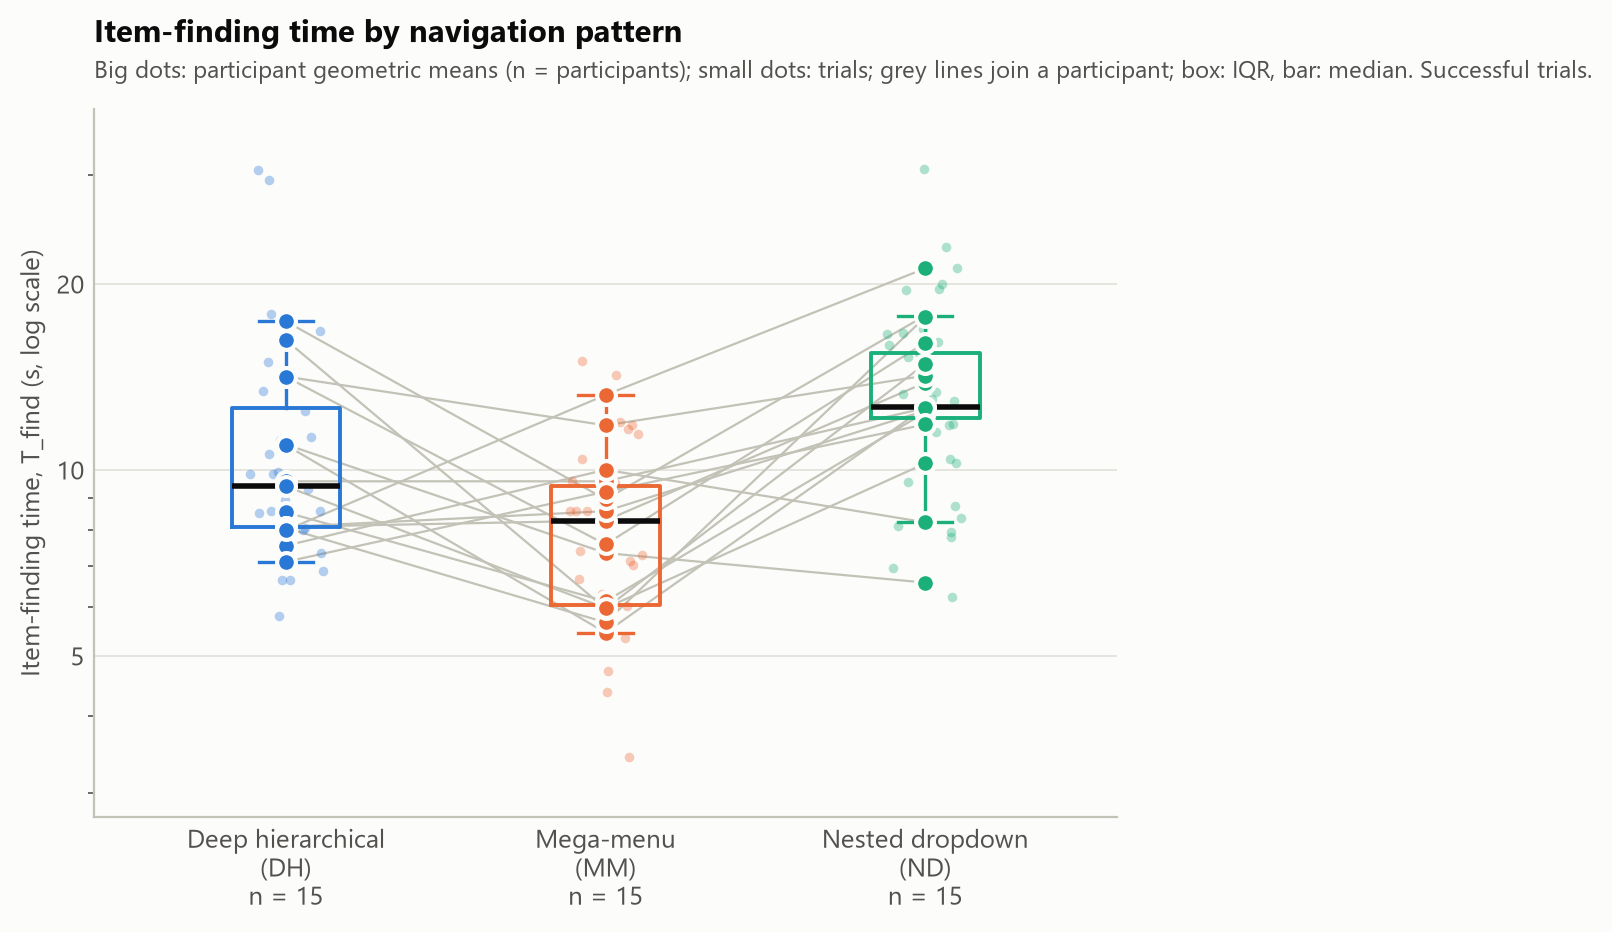

In [10]:
display(Image(filename=str(paths['F1_tfind_by_pattern'])))

### F2: H2: errors
Left: how often trials were error-free. Right: mean errors with 95% CI; overlapping intervals mean the pattern difference is uncertain.

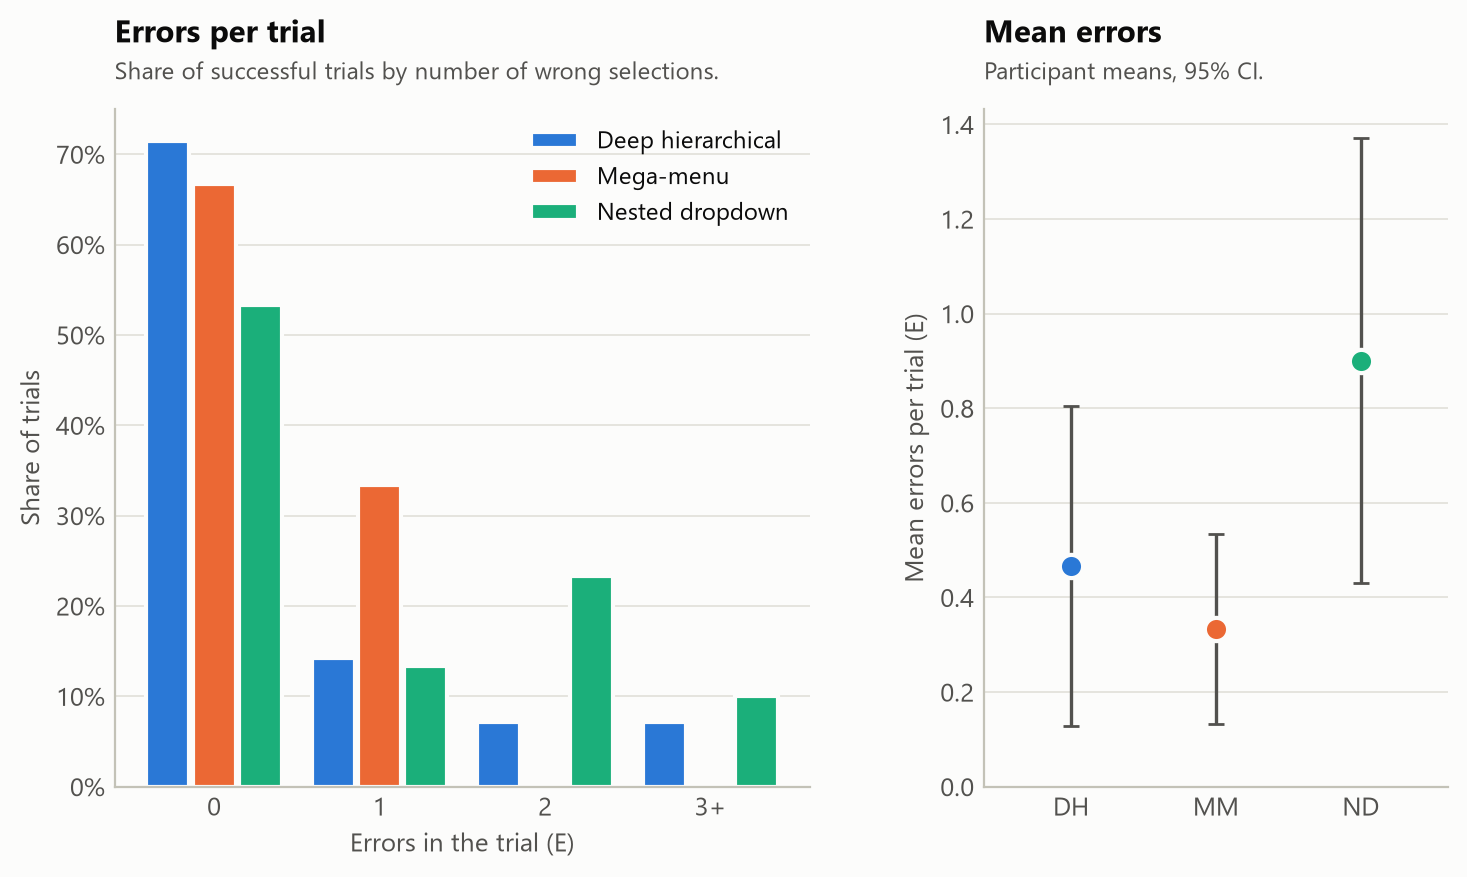

In [11]:
display(Image(filename=str(paths['F2_errors_by_pattern'])))

### F3: H3 / RQ3: recovery time
Only trials with at least one error contribute. Check the n under each pattern; small n means a wide, unreliable box.

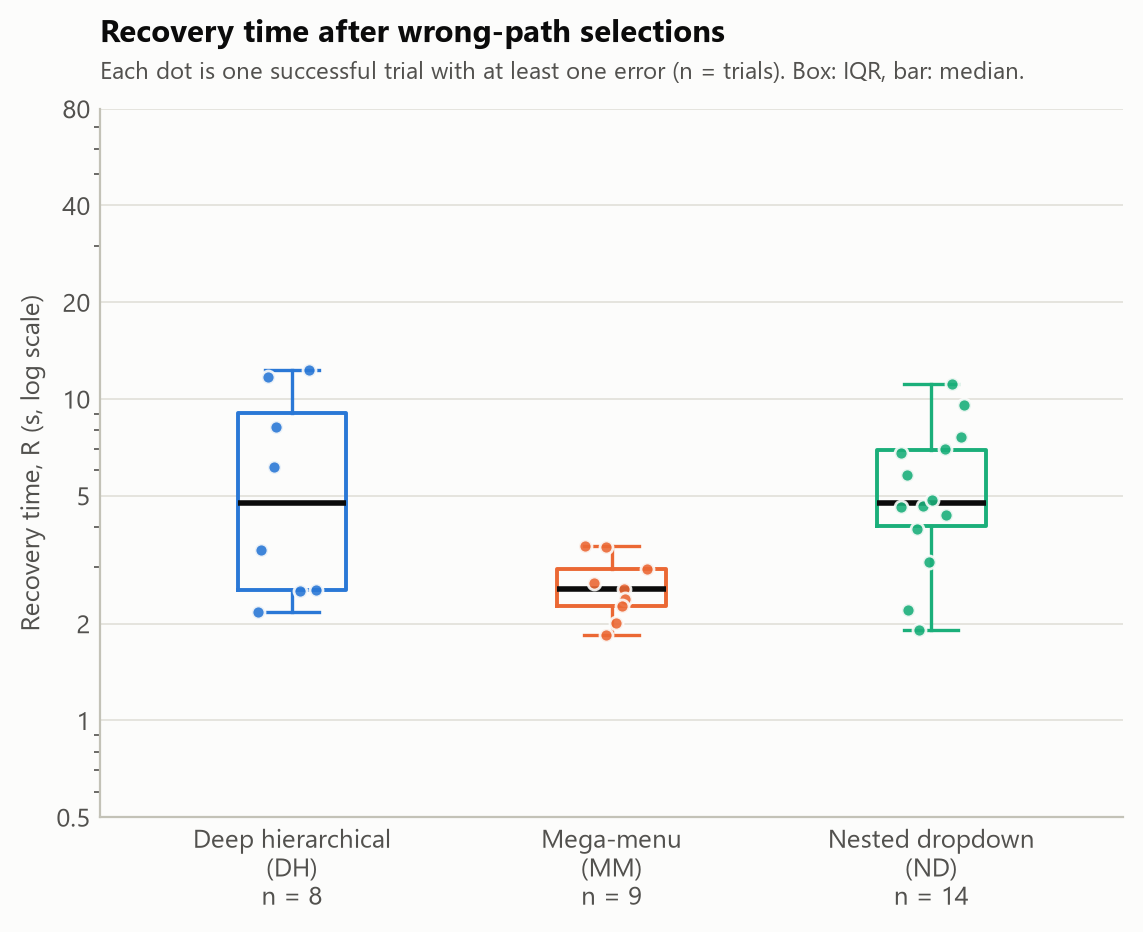

In [12]:
display(Image(filename=str(paths['F3_recovery_time'])))

### F4: Eq. 2: recovery or slower correct navigation?
If the hatched (recovery) part differs a lot between patterns but the solid part does not, recovery drives the gap; if the solid part differs, correct navigation itself is slower.

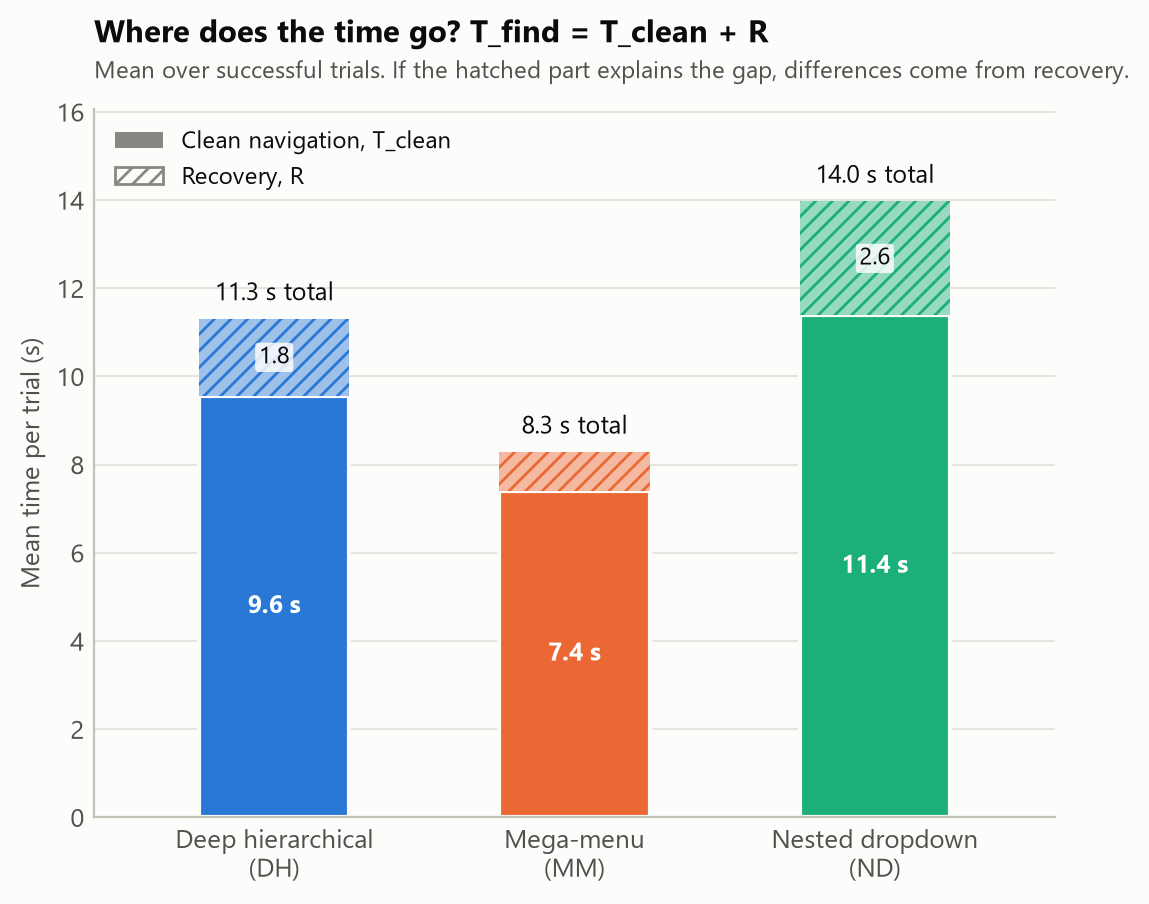

In [13]:
display(Image(filename=str(paths['F4_clean_vs_recovery'])))

### F5: Task success
Failures (give-up, time-out) are excluded from the time and error analyses, so check that they are not concentrated in one pattern.

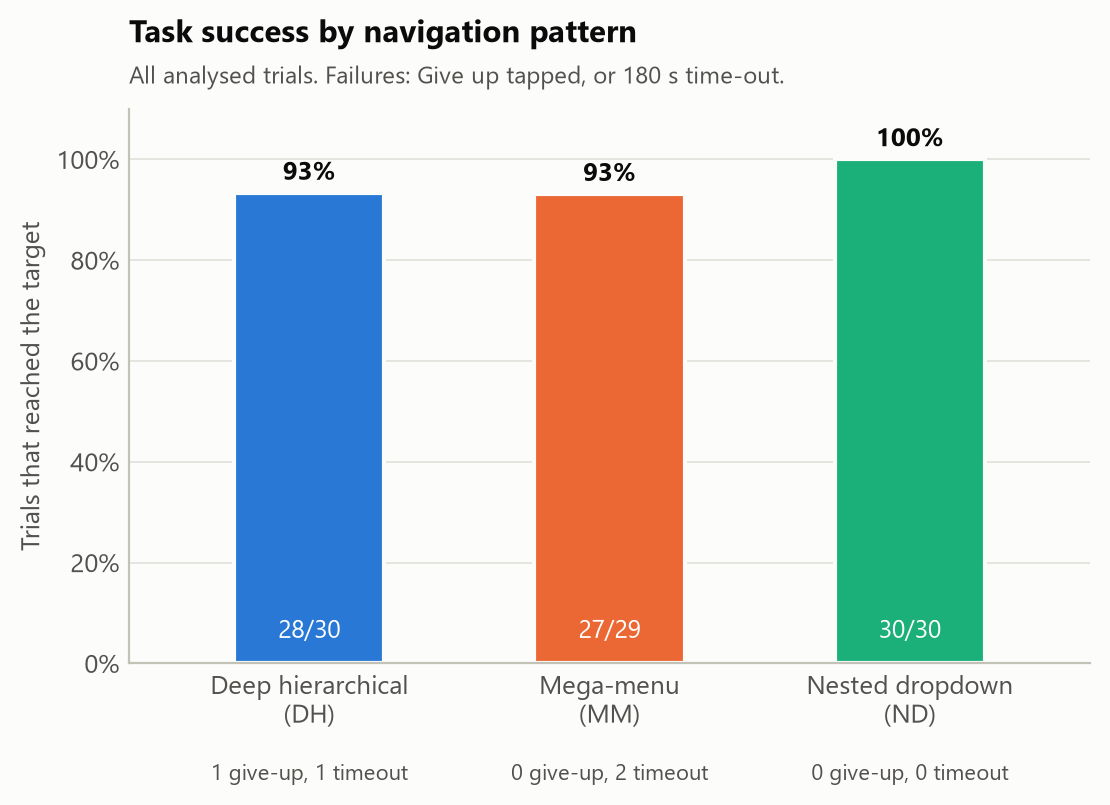

In [14]:
display(Image(filename=str(paths['F5_success'])))

### F6: Perceived difficulty (SEQ)
More blue = easier. Secondary outcome, supports rather than tests a hypothesis.

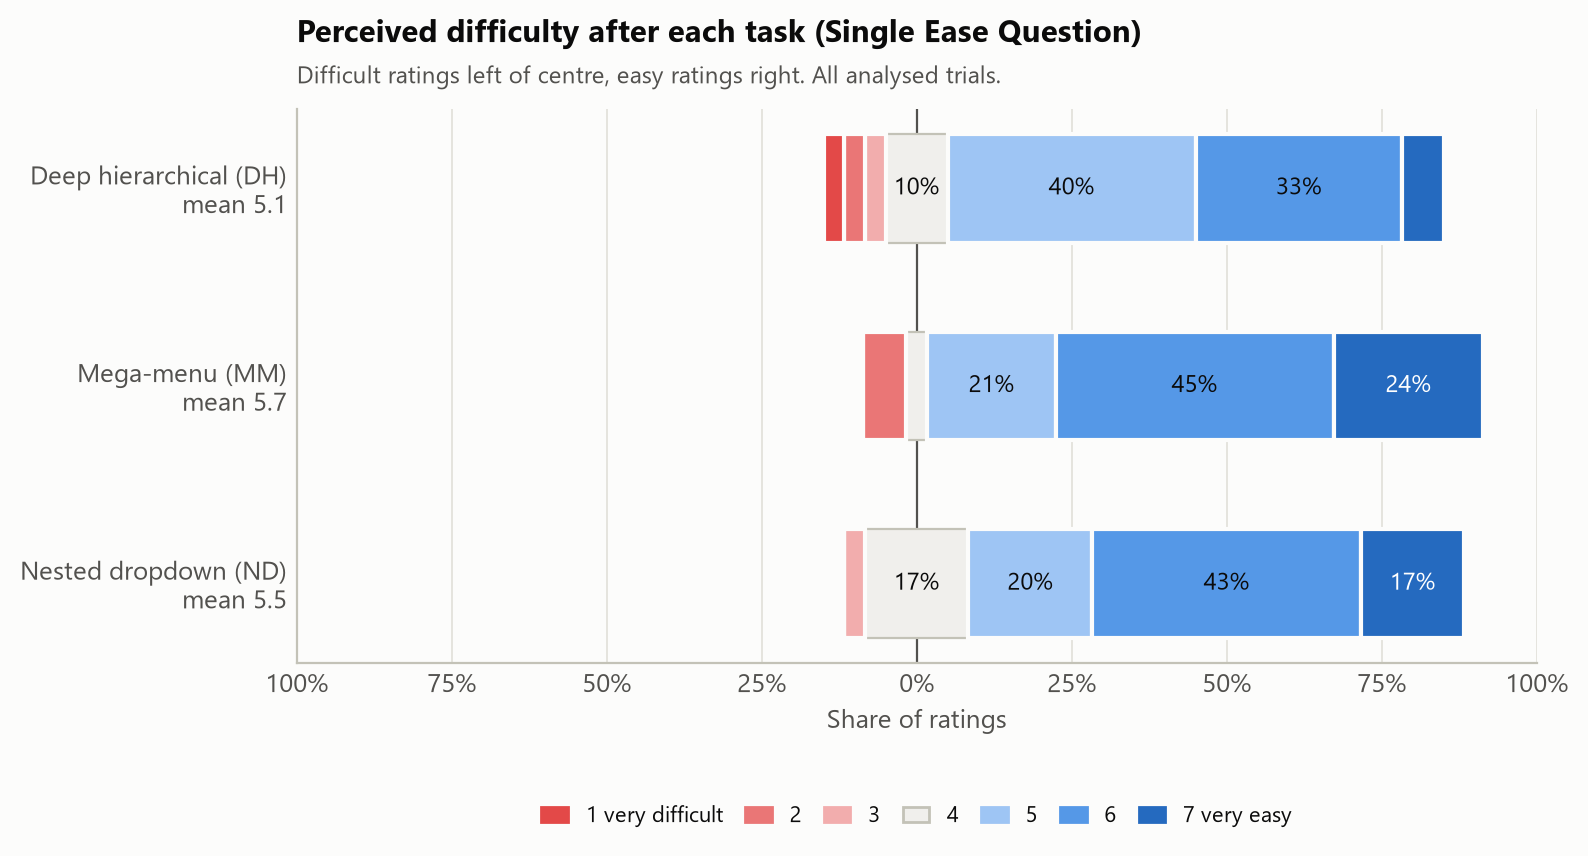

In [15]:
display(Image(filename=str(paths['F6_difficulty_ratings'])))

### F7: Preference ranking
Counts of participants giving each rank. Secondary outcome.

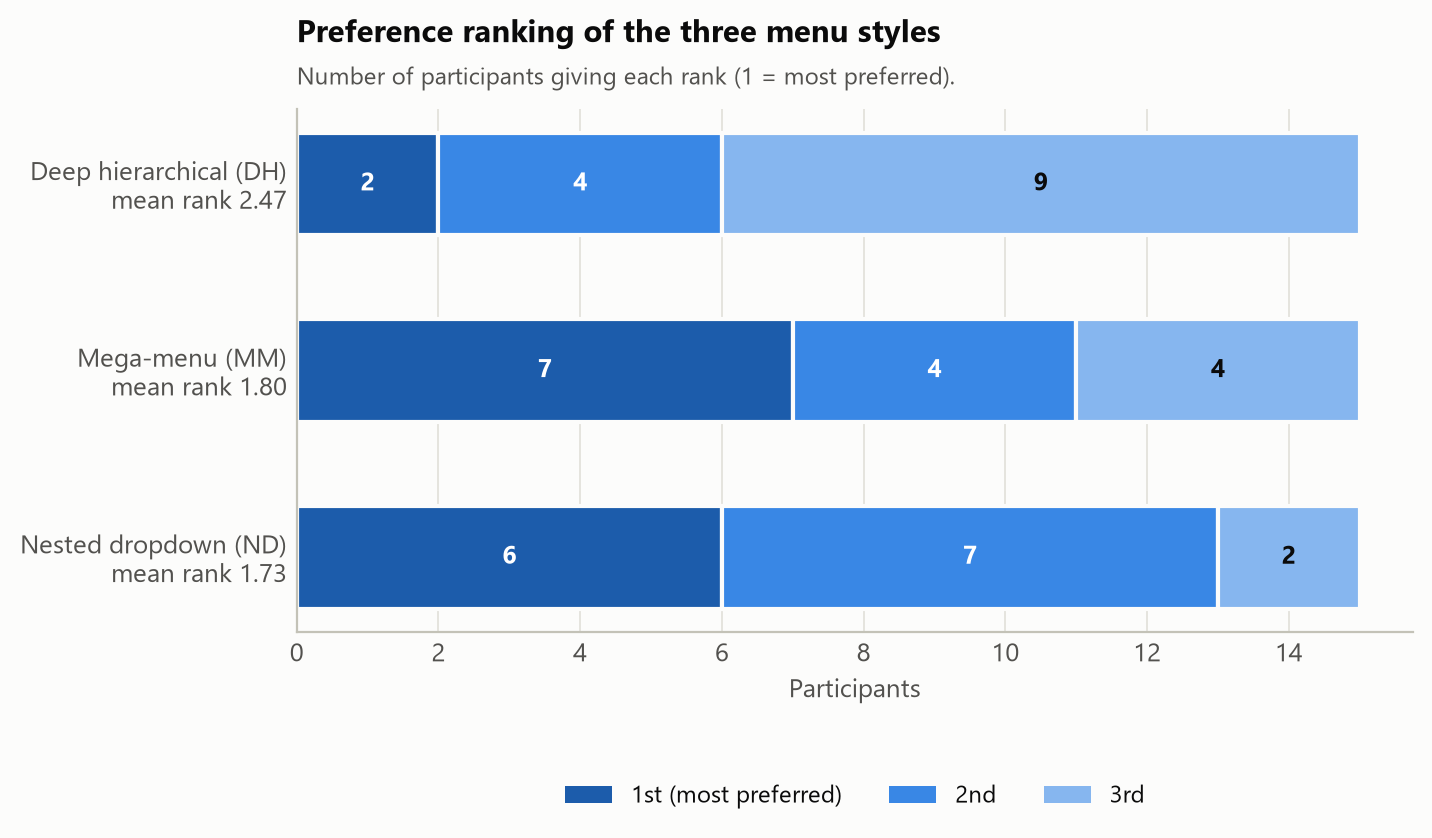

In [16]:
display(Image(filename=str(paths['F7_preference_ranking'])))

### F8: Order / task-pair check
Block position and task pair are the same factor in this design (Table 3), so a drop over blocks could be either learning or an easier task pair. Large gaps here are a limitation to report.

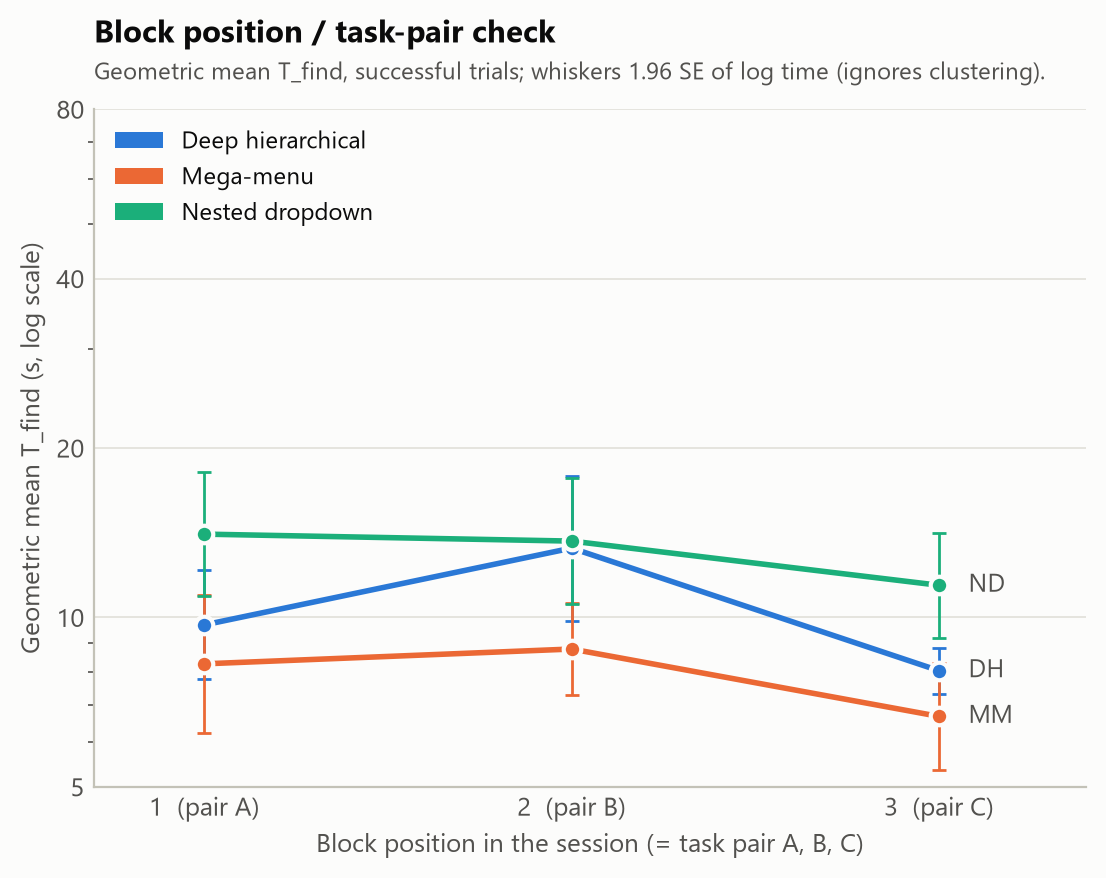

In [17]:
display(Image(filename=str(paths['F8_order_and_task_pair'])))

### F9: Path analysis: where errors happen
Which level of the tree causes the wrong selections for each pattern.

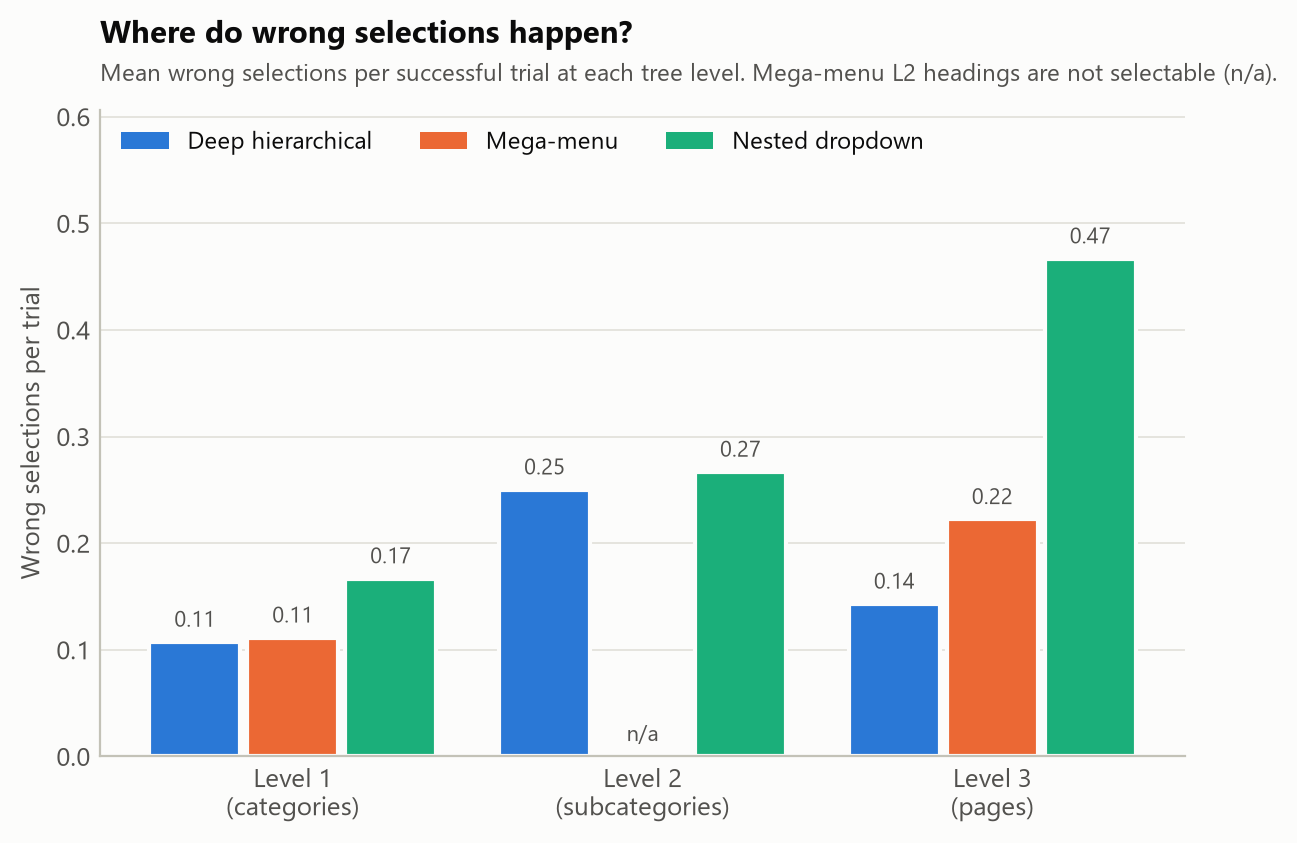

In [18]:
display(Image(filename=str(paths['F9_errors_by_tree_level'])))

### F10: Path analysis: misleading items
Items that were repeatedly chosen by mistake are candidates for unclear labels; use this in the Discussion.

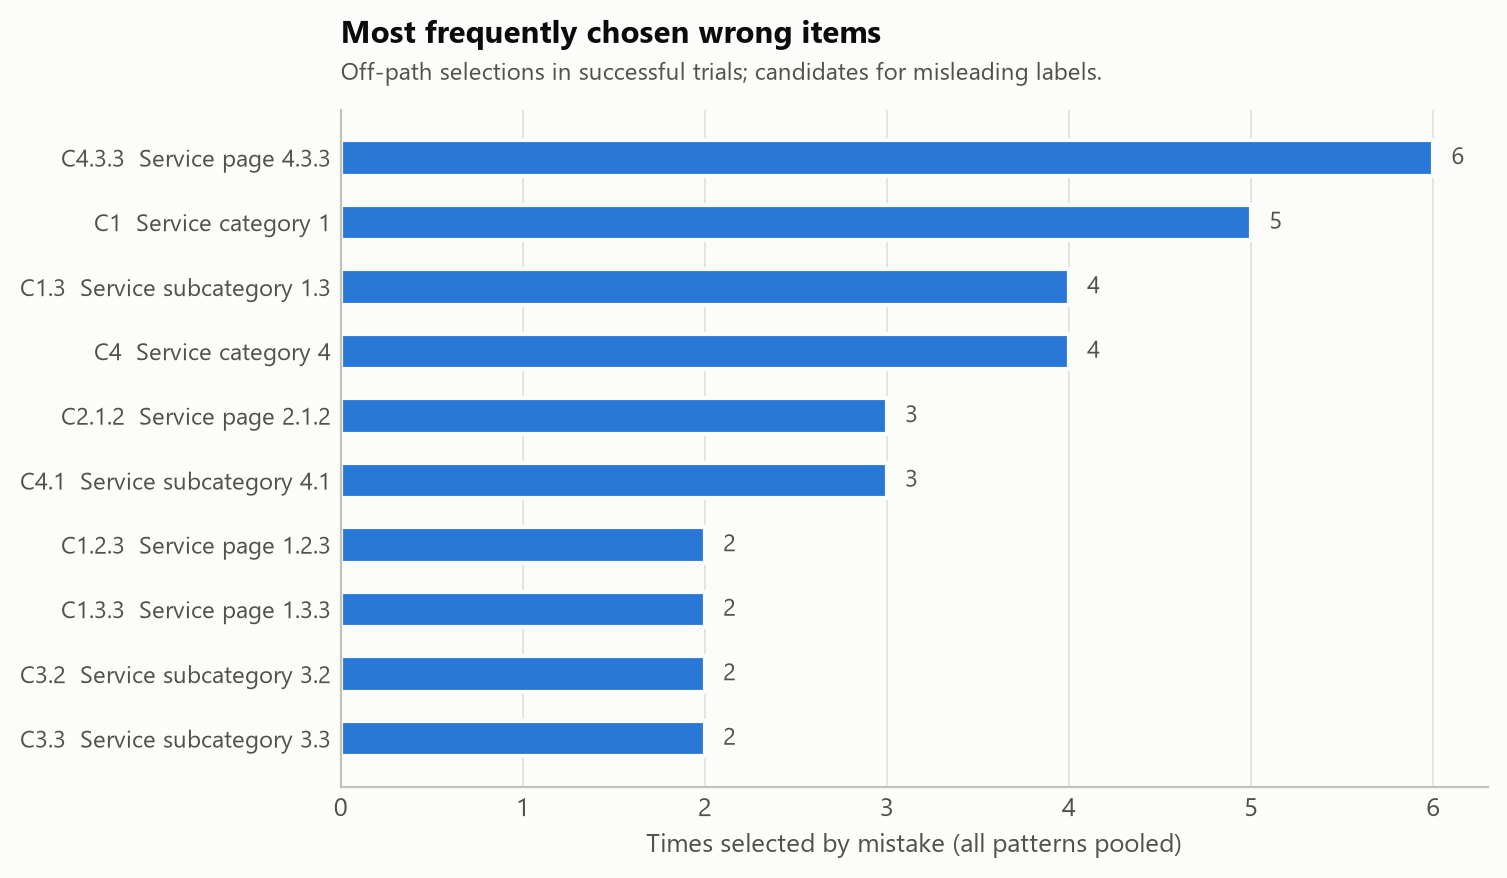

In [19]:
display(Image(filename=str(paths['F10_most_chosen_wrong_items'])))